In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

!pip install --upgrade certifi


In [2]:

import urllib.request
import ssl
import os

url = "https://www.crcv.ucf.edu/data/ucf_sports_actions.zip"
output_path = "/kaggle/working/ucf_sports_actions.zip"

context = ssl._create_unverified_context()

with urllib.request.urlopen(url, context=context, timeout=120) as response:
    with open(output_path, "wb") as f:
        while True:
            chunk = response.read(1024 * 1024)
            if not chunk:
                break
            f.write(chunk)

print("Downloaded file size (MB):",
      round(os.path.getsize(output_path) / (1024**2), 2))


Downloaded file size (MB): 1695.25


In [3]:
print(output_path)

/kaggle/working/ucf_sports_actions.zip


In [10]:

# Step 2: Extract the dataset
import zipfile
print(os.listdir("/kaggle/working"))
print(os.path.exists("/kaggle/working/ucf_sports_actions.zip"))
ZIP_PATH = "/kaggle/working/ucf_sports_actions.zip"
DATASET_DIR = "/kaggle/working/UCF_Sports_Action"
os.makedirs(DATASET_DIR, exist_ok=True)

if not os.listdir(DATASET_DIR):
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATASET_DIR)
    print("Extraction completed.")
else:
    print("Dataset is already extracted.")

# Step 3: Display dataset location
print("\nDataset path:", DATASET_DIR)
print("Top-level contents:", os.listdir(DATASET_DIR))


['UCF_Sports_Action', '.virtual_documents', 'ucf_sports_actions.zip']
True
Extracting dataset...
Extraction completed.

Dataset path: /kaggle/working/UCF_Sports_Action
Top-level contents: ['ucf_sports_actions']


In [11]:
import os, sys, json, time, random, re, shutil, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import binomtest

warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda Tesla T4


In [12]:
CFG = dict(
    data_root=None,                   # None = auto-detect under /kaggle/input
    work_dir="/kaggle/working/UCF_Sports_Action" if Path("/kaggle/working").exists() else "./work",
    resume_from=None,                 # e.g. "/kaggle/input/<previous-output>/results" to continue a run
    cache_short_side=256,             # frames are decoded once and cached at this short side
    n_folds=5,
    fold_seed=42,                     # fixes the folds; identical for every model (needed for paired tests)
    seeds=[0],                        # training seeds; use [0, 1] or [0, 1, 2] if GPU quota allows
    # ---- SlowFast-Lite training (identical for every configuration) ----
    epochs=50,
    batch_size=8,
    lr=1e-3,
    weight_decay=1e-4,
    lr_milestones=[20, 40],           # 1e-3 -> 5e-4 -> 2.5e-4 (as in the original manuscript)
    lr_gamma=0.5,
    label_smoothing=0.0,
    selection="last",                 # "last" = fixed final epoch (no leakage); "val" = best inner-validation macro-F1
    val_fraction=0.15,                # only used when selection == "val"
    crop_size=112,
    resize_short=128,
    test_views=1,                     # 1 centre clip keeps the temporal-window ablation clean
    num_workers=min(4, os.cpu_count() or 2),
    amp=True,
    # ---- what to run ----
    run_slowfast_ablation=True,
    run_pretrained_probe=True,
    run_pretrained_finetune=False,    # optional, costs more GPU time
    pretrained_models=["r2plus1d_18", "s3d", "mvit_v2_s", "swin3d_t",
                       "timesformer", "videomae", "slowfast_r50"],
    finetune_models=["r2plus1d_18", "swin3d_t"],
    finetune_epochs=20,
    finetune_lr=1e-4,
    n_bootstrap=10000,
)

# SlowFast-Lite configurations.
# t_fast  : frames given to the fast pathway (slow pathway gets t_fast / alpha)
# window  : span of source frames the clip is sampled from (None = whole video)
# slow_w  : base channel width of the slow pathway (stages use w, 2w, 4w, 8w)
# fast_w  : base channel width of the fast pathway (beta = fast_w / slow_w)
# The temporal-window variants keep t_fast fixed, so they change temporal context but not compute.
# The pathway-dominance variants shift channel capacity between pathways; params/GFLOPs are
# reported so capacity effects can be discussed openly (Reviewer 1).
# >>> If you recall the exact settings of the original study, edit them here and describe them
#     in the Methods table of the manuscript. <<<
SLOWFAST_CONFIGS = {
    # baseline: beta = 3/22 ~ 1/8 as in Feichtenhofer et al.; ~1.11 M params (original manuscript: 1,156,749)
    "Baseline":        dict(alpha=4, t_fast=32, window=64,   slow_w=22, fast_w=3,  use_slow=True,  use_fast=True),
    "Fast-Dominant":   dict(alpha=4, t_fast=32, window=64,   slow_w=11, fast_w=11, use_slow=True,  use_fast=True),
    "Slow-Dominant":   dict(alpha=4, t_fast=32, window=64,   slow_w=24, fast_w=2,  use_slow=True,  use_fast=True),
    "Small-Window":    dict(alpha=4, t_fast=32, window=32,   slow_w=22, fast_w=3,  use_slow=True,  use_fast=True),
    "Large-Window":    dict(alpha=4, t_fast=32, window=None, slow_w=22, fast_w=3,  use_slow=True,  use_fast=True),
    "Slow-Only":       dict(alpha=4, t_fast=32, window=64,   slow_w=22, fast_w=3,  use_slow=True,  use_fast=False),
    "Fast-Only":       dict(alpha=4, t_fast=32, window=64,   slow_w=22, fast_w=3,  use_slow=False, use_fast=True),
}
BASELINE_NAME = "Baseline"

WORK = Path(CFG["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
CACHE = WORK / "frame_cache"; CACHE.mkdir(exist_ok=True)
RES = WORK / "results"; RES.mkdir(exist_ok=True)
(RES / "predictions").mkdir(exist_ok=True)
(RES / "histories").mkdir(exist_ok=True)
(RES / "figures").mkdir(exist_ok=True)
(RES / "tables").mkdir(exist_ok=True)

if CFG["resume_from"] and Path(CFG["resume_from"]).exists():
    shutil.copytree(CFG["resume_from"], RES, dirs_exist_ok=True)
    print("Resumed previous results from", CFG["resume_from"])

with open(RES / "config.json", "w") as f:
    json.dump(dict(CFG=CFG, SLOWFAST_CONFIGS=SLOWFAST_CONFIGS), f, indent=2)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

In [14]:

CFG["data_root"] = "/kaggle/working/UCF_Sports_Action"

root = find_dataset_root(CFG["data_root"])

print("Dataset root:", root)
index_df = build_index(root)

print("Total indexed videos:", len(index_df))
print(index_df.head())

CLASS_NAMES = ["Diving-Side", "Golf-Swing-Back", "Golf-Swing-Front", "Golf-Swing-Side",
               "Kicking-Front", "Kicking-Side", "Lifting", "Riding-Horse", "Run-Side",
               "SkateBoarding-Front", "Swing-Bench", "Swing-SideAngle", "Walk-Front"]
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
VID_EXT = (".avi", ".mp4", ".mpg", ".mpeg", ".mov", ".vob", ".mkv")
IGNORE_DIRS = {"gt", "__macosx"}


def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]


def norm(name):
    return re.sub(r"[^a-z]", "", name.lower())


def find_dataset_root(start):
    """Return the directory whose sub-folders are the 13 UCF Sports classes."""
    wanted = {norm(c) for c in CLASS_NAMES}
    best, best_hits = None, 0
    for dirpath, dirnames, _ in os.walk(start):
        hits = len(wanted & {norm(d) for d in dirnames})
        if hits > best_hits:
            best, best_hits = dirpath, hits
        if hits == len(wanted):
            break
    if best_hits < 10:
        raise FileNotFoundError(f"Could not find the UCF Sports class folders under {start}")
    return Path(best)


def collect_images(folder):
    imgs = []
    for dirpath, dirnames, filenames in os.walk(folder):
        dirnames[:] = [d for d in dirnames if d.lower() not in IGNORE_DIRS]
        imgs += [Path(dirpath) / f for f in filenames if f.lower().endswith(IMG_EXT)]
    # if frames exist both at top level and in a sub-folder (e.g. 'jpeg/'), keep the larger set from one folder
    by_parent = {}
    for p in imgs:
        by_parent.setdefault(p.parent, []).append(p)
    if not by_parent:
        return []
    frames = max(by_parent.values(), key=len)
    return sorted(frames, key=natural_key)


def build_index(root):
    class_dirs = {norm(d.name): d for d in root.iterdir() if d.is_dir()}
    rows = []
    for label, cname in enumerate(CLASS_NAMES):
        cdir = class_dirs.get(norm(cname))
        if cdir is None:
            print("WARNING: missing class folder", cname); continue
        # layout A: one sub-folder per video (original archive)
        for vdir in sorted([d for d in cdir.iterdir() if d.is_dir()], key=natural_key):
            frames = collect_images(vdir)
            vids = sorted([p for p in vdir.rglob("*") if p.suffix.lower() in VID_EXT], key=natural_key)
            if len(frames) >= 8:
                rows.append(dict(cls=cname, label=label, source="frames", path=str(vdir), n_src=len(frames)))
            elif vids:
                rows.append(dict(cls=cname, label=label, source="video", path=str(vids[0]), n_src=-1))
        # layout B: video files directly inside the class folder
        for v in sorted([p for p in cdir.iterdir() if p.suffix.lower() in VID_EXT], key=natural_key):
            rows.append(dict(cls=cname, label=label, source="video", path=str(v), n_src=-1))
    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError(f"No videos found under {root}")
    df.insert(0, "video_id", [f"{c}__{i:03d}" for c, i in
                              zip(df.cls, df.groupby("cls").cumcount())])
    return df


search_start = CFG["data_root"] or ("/kaggle/input" if Path("/kaggle/input").exists() else ".")
root = find_dataset_root(search_start)
print("Dataset root:", root)
index_df = build_index(root)
print(f"Videos found: {len(index_df)} (manuscript reports 143)")
print(index_df.cls.value_counts().reindex(CLASS_NAMES).to_string())

Dataset root: /kaggle/working/UCF_Sports_Action/ucf_sports_actions/ucf action
Total indexed videos: 150
           video_id          cls  label  source  \
0  Diving-Side__000  Diving-Side      0  frames   
1  Diving-Side__001  Diving-Side      0  frames   
2  Diving-Side__002  Diving-Side      0  frames   
3  Diving-Side__003  Diving-Side      0  frames   
4  Diving-Side__004  Diving-Side      0  frames   

                                                path  n_src  
0  /kaggle/working/UCF_Sports_Action/ucf_sports_a...     55  
1  /kaggle/working/UCF_Sports_Action/ucf_sports_a...     55  
2  /kaggle/working/UCF_Sports_Action/ucf_sports_a...     55  
3  /kaggle/working/UCF_Sports_Action/ucf_sports_a...     55  
4  /kaggle/working/UCF_Sports_Action/ucf_sports_a...     55  
Dataset root: /kaggle/working/UCF_Sports_Action/ucf_sports_actions/ucf action
Videos found: 150 (manuscript reports 143)
cls
Diving-Side            14
Golf-Swing-Back         5
Golf-Swing-Front        8
Golf-Swing-Sid

In [15]:
def resize_short(img, short):
    h, w = img.shape[:2]
    s = short / min(h, w)
    return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)


def load_frames(row, short):
    out = []
    if row.source == "frames":
        for p in collect_images(Path(row.path)):
            img = cv2.imread(str(p))
            if img is not None:
                out.append(resize_short(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), short))
    else:
        cap = cv2.VideoCapture(row.path)
        while True:
            ok, img = cap.read()
            if not ok:
                break
            out.append(resize_short(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), short))
        cap.release()
    if not out:
        raise RuntimeError(f"No frames decoded from {row.path}")
    shapes = Counter(f.shape for f in out)          # guard against odd-sized frames
    target = shapes.most_common(1)[0][0]
    out = [f if f.shape == target else cv2.resize(f, (target[1], target[0])) for f in out]
    return np.stack(out)


n_frames, cache_paths = [], []
t0 = time.time()
for row in index_df.itertuples():
    cp = CACHE / f"{row.video_id}.npy"
    if not cp.exists():
        np.save(cp, load_frames(row, CFG["cache_short_side"]))
    arr = np.load(cp, mmap_mode="r")
    n_frames.append(arr.shape[0]); cache_paths.append(str(cp))
index_df["n_frames"] = n_frames
index_df["cache"] = cache_paths
index_df.to_csv(RES / "video_index.csv", index=False)
print(f"Cached {len(index_df)} videos in {time.time() - t0:.0f}s")
print(index_df.n_frames.describe().round(1).to_string())

Cached 150 videos in 63s
count    150.0
mean      63.9
std       24.7
min       22.0
25%       50.0
50%       60.0
75%       75.0
max      144.0


In [16]:
#Cross-validation folds (fixed and shared by every model)
skf = StratifiedKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["fold_seed"])
index_df["fold"] = -1
for k, (_, te) in enumerate(skf.split(index_df, index_df.label)):
    index_df.loc[index_df.index[te], "fold"] = k
index_df[["video_id", "cls", "label", "n_frames", "fold"]].to_csv(RES / "folds.csv", index=False)
print(pd.crosstab(index_df.cls, index_df.fold).reindex(CLASS_NAMES))

for name, c in SLOWFAST_CONFIGS.items():
    w = c["window"]
    span = index_df.n_frames if w is None else index_df.n_frames.clip(upper=w)
    print(f"{name:14s} window={str(w):5s} mean effective span = {span.mean():5.1f} frames; "
          f"videos shorter than window = {(index_df.n_frames < (w or 0)).sum()}")

fold                 0  1  2  3  4
cls                               
Diving-Side          3  3  3  3  2
Golf-Swing-Back      1  1  1  1  1
Golf-Swing-Front     2  2  1  1  2
Golf-Swing-Side      1  1  1  1  1
Kicking-Front        2  2  2  2  2
Kicking-Side         2  2  2  2  2
Lifting              1  1  2  1  1
Riding-Horse         2  2  2  3  3
Run-Side             3  3  3  2  2
SkateBoarding-Front  2  2  2  3  3
Swing-Bench          4  4  4  4  4
Swing-SideAngle      3  3  3  2  2
Walk-Front           4  4  4  5  5
Baseline       window=64    mean effective span =  55.0 frames; videos shorter than window = 84
Fast-Dominant  window=64    mean effective span =  55.0 frames; videos shorter than window = 84
Slow-Dominant  window=64    mean effective span =  55.0 frames; videos shorter than window = 84
Small-Window   window=32    mean effective span =  30.8 frames; videos shorter than window = 20
Large-Window   window=None  mean effective span =  63.9 frames; videos shorter than window 

In [17]:
def sample_indices(n, num_frames, window, train, rng, pos=0.5):
    span = n if window is None else min(window, n)
    if train:
        start = int(rng.integers(0, n - span + 1))
    else:
        start = int(round((n - span) * pos))
    idx = np.linspace(start, start + span - 1, num_frames)
    return np.clip(np.round(idx).astype(int), 0, n - 1)


def transform_clip(frames, train, crop, short, mean, std, rng, flip=False):
    """frames: (T,H,W,3) uint8 -> (3,T,crop,crop) float tensor."""
    x = torch.from_numpy(np.ascontiguousarray(frames)).permute(0, 3, 1, 2).float().div_(255.0)
    s = short * (rng.uniform(1.0, 1.25) if train else 1.0)
    h, w = x.shape[-2:]
    sc = s / min(h, w)
    nh, nw = max(crop, int(round(h * sc))), max(crop, int(round(w * sc)))
    x = F.interpolate(x, size=(nh, nw), mode="bilinear", align_corners=False, antialias=True)
    if train:
        top, left = int(rng.integers(0, nh - crop + 1)), int(rng.integers(0, nw - crop + 1))
    else:
        top, left = (nh - crop) // 2, (nw - crop) // 2
    x = x[..., top:top + crop, left:left + crop]
    if (train and rng.random() < 0.5) or flip:
        x = torch.flip(x, dims=[-1])
    if train:                                          # mild photometric jitter, same for whole clip
        b, c = rng.uniform(0.85, 1.15), rng.uniform(0.85, 1.15)
        m = x.mean()
        x = ((x - m) * c + m) * b
        x = x.clamp_(0, 1)
    mean = torch.tensor(mean).view(1, 3, 1, 1); std = torch.tensor(std).view(1, 3, 1, 1)
    x = (x - mean) / std
    return x.permute(1, 0, 2, 3).contiguous()


IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class ClipDataset(Dataset):
    def __init__(self, df, num_frames, window, train, crop, short,
                 mean=IMAGENET_MEAN, std=IMAGENET_STD, pos=0.5, flip=False):
        self.df = df.reset_index(drop=True)
        self.kw = dict(num_frames=num_frames, window=window, train=train, crop=crop,
                       short=short, mean=mean, std=std, pos=pos, flip=flip)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]; k = self.kw
        rng = np.random.default_rng(torch.randint(0, 2**31 - 1, (1,)).item())
        arr = np.load(r.cache, mmap_mode="r")
        idx = sample_indices(arr.shape[0], k["num_frames"], k["window"], k["train"], rng, k["pos"])
        clip = transform_clip(arr[idx], k["train"], k["crop"], k["short"], k["mean"], k["std"], rng, k["flip"])
        return clip, int(r.label), i


def make_loader(ds, shuffle, bs):
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=CFG["num_workers"],
                      pin_memory=DEVICE.type == "cuda", drop_last=False,
                      persistent_workers=CFG["num_workers"] > 0)

In [18]:
#SlowFast-Lite (trained from scratch)
def conv_bn_relu(cin, cout, k, s, p):
    return nn.Sequential(nn.Conv3d(cin, cout, k, s, p, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True))


class BasicBlock3D(nn.Module):
    def __init__(self, cin, cout, kt, stride):
        super().__init__()
        self.conv1 = conv_bn_relu(cin, cout, (kt, 3, 3), (1, stride, stride), (kt // 2, 1, 1))
        self.conv2 = nn.Sequential(nn.Conv3d(cout, cout, (1, 3, 3), 1, (0, 1, 1), bias=False), nn.BatchNorm3d(cout))
        self.short = None
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(nn.Conv3d(cin, cout, 1, (1, stride, stride), bias=False), nn.BatchNorm3d(cout))
        nn.init.zeros_(self.conv2[1].weight)               # residual starts as identity

    def forward(self, x):
        idt = x if self.short is None else self.short(x)
        return F.relu(self.conv2(self.conv1(x)) + idt, inplace=True)


class Stem(nn.Module):
    def __init__(self, cout, kt):
        super().__init__()
        self.conv = conv_bn_relu(3, cout, (kt, 7, 7), (1, 2, 2), (kt // 2, 3, 3))
        self.pool = nn.MaxPool3d((1, 3, 3), (1, 2, 2), (0, 1, 1))

    def forward(self, x):
        return self.pool(self.conv(x))


class SlowFastLite(nn.Module):
    def __init__(self, num_classes, alpha=4, slow_w=32, fast_w=4, use_slow=True, use_fast=True,
                 dropout=0.5, **_):
        super().__init__()
        assert use_slow or use_fast
        self.alpha, self.use_slow, self.use_fast = alpha, use_slow, use_fast
        self.lateral = use_slow and use_fast
        sw = [slow_w * m for m in (1, 2, 4, 8)]
        fw = [fast_w * m for m in (1, 2, 4, 8)]
        slow_kt, strides = (1, 1, 3, 3), (1, 2, 2, 2)
        out_dim = 0
        if use_fast:
            self.f_stem = Stem(fw[0], 5)
            self.f_stages = nn.ModuleList([BasicBlock3D(fw[i - 1] if i else fw[0], fw[i], 3, strides[i]) for i in range(4)])
            out_dim += fw[-1]
        if use_slow:
            self.s_stem = Stem(sw[0], 1)
            f_in = [fw[0], fw[0], fw[1], fw[2]]                             # fast channels entering stage i
            extra = [2 * f_in[i] if self.lateral else 0 for i in range(4)]  # lateral channels added to slow stage i
            self.s_stages = nn.ModuleList([BasicBlock3D((sw[i - 1] if i else sw[0]) + extra[i], sw[i], slow_kt[i], strides[i]) for i in range(4)])
            out_dim += sw[-1]
        if self.lateral:
            f_in = [fw[0], fw[0], fw[1], fw[2]]
            self.laterals = nn.ModuleList([conv_bn_relu(f_in[i], 2 * f_in[i], (5, 1, 1), (alpha, 1, 1), (2, 0, 0)) for i in range(4)])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(out_dim, num_classes)

    def forward(self, x):                      # x: (B,3,T_fast,H,W)
        xs = x[:, :, ::self.alpha] if self.use_slow else None
        xf = x if self.use_fast else None
        if self.use_fast: xf = self.f_stem(xf)
        if self.use_slow: xs = self.s_stem(xs)
        for i in range(4):
            if self.lateral:
                xs = torch.cat([xs, self.laterals[i](xf)], dim=1)
            if self.use_slow: xs = self.s_stages[i](xs)
            if self.use_fast: xf = self.f_stages[i](xf)
        feats = []
        if self.use_slow: feats.append(F.adaptive_avg_pool3d(xs, 1).flatten(1))
        if self.use_fast: feats.append(F.adaptive_avg_pool3d(xf, 1).flatten(1))
        return self.fc(self.dropout(torch.cat(feats, 1)))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def count_gflops(model, inp):
    """Forward GFLOPs (1 multiply-add = 2 FLOPs) for one clip."""
    try:
        from torch.utils.flop_counter import FlopCounterMode
        model = model.eval()
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            model(inp)
        return fc.get_total_flops() / 1e9
    except Exception as e:
        print("FLOP count unavailable:", e); return float("nan")


arch_rows = []
for name, c in SLOWFAST_CONFIGS.items():
    m = SlowFastLite(len(CLASS_NAMES), **c)
    x = torch.zeros(1, 3, c["t_fast"], CFG["crop_size"], CFG["crop_size"])
    arch_rows.append(dict(config=name, alpha=c["alpha"], T_fast=c["t_fast"],
                          T_slow=c["t_fast"] // c["alpha"] if c["use_slow"] else 0,
                          window=c["window"] or "full video",
                          slow_width=c["slow_w"] if c["use_slow"] else 0,
                          fast_width=c["fast_w"] if c["use_fast"] else 0,
                          beta=round(c["fast_w"] / c["slow_w"], 3) if c["use_slow"] and c["use_fast"] else "-",
                          params=count_params(m), GFLOPs=round(count_gflops(m, x), 2)))
arch_df = pd.DataFrame(arch_rows)
arch_df.to_csv(RES / "tables" / "architecture_configs.csv", index=False)
print(arch_df.to_string(index=False))

       config  alpha  T_fast  T_slow     window  slow_width  fast_width   beta  params  GFLOPs
     Baseline      4      32       8         64          22           3  0.136 1108794    1.26
Fast-Dominant      4      32       8         64          11          11    1.0  789120    2.72
Slow-Dominant      4      32       8         64          24           2  0.083 1232359    1.18
 Small-Window      4      32       8         32          22           3  0.136 1108794    1.26
 Large-Window      4      32       8 full video          22           3  0.136 1108794    1.26
    Slow-Only      4      32       8         64          22           0      -  933891    0.68
    Fast-Only      4      32       0         64           0           3      -   20512    0.49


In [20]:
#Training and evaluation of one fold
def predict(model, df, num_frames, window, crop, short, mean, std, views, input_fn=None):
    """Average softmax over temporal positions and (if views>1) horizontal flips."""
    model.eval()
    positions = [0.5] if views == 1 else list(np.linspace(0.0, 1.0, views))
    probs = np.zeros((len(df), len(CLASS_NAMES)))
    for pos in positions:
        ds = ClipDataset(df, num_frames, window, False, crop, short, mean, std, pos=pos)
        for x, _, i in make_loader(ds, False, CFG["batch_size"]):
            x = x.to(DEVICE, non_blocking=True)
            with torch.no_grad(), torch.autocast(DEVICE.type, enabled=CFG["amp"] and DEVICE.type == "cuda"):
                out = model(input_fn(x) if input_fn else x)
            probs[i.numpy()] += out.float().softmax(1).cpu().numpy()
    return probs / len(positions)


def train_fold(model, train_df, test_df, num_frames, window, crop, short, epochs, lr,
               mean=IMAGENET_MEAN, std=IMAGENET_STD, param_groups=None, input_fn=None, tag=""):
    model = model.to(DEVICE)
    val_df = None
    if CFG["selection"] == "val":
        sss = StratifiedShuffleSplit(1, test_size=CFG["val_fraction"], random_state=0)
        tr, va = next(sss.split(train_df, train_df.label))
        val_df, train_df = train_df.iloc[va], train_df.iloc[tr]
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    milestones = [m for m in CFG["lr_milestones"] if m < epochs] if epochs == CFG["epochs"] else [int(epochs * 0.6), int(epochs * 0.85)]
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=milestones, gamma=CFG["lr_gamma"])
    scaler = torch.amp.GradScaler(enabled=CFG["amp"] and DEVICE.type == "cuda")
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    loader = make_loader(ClipDataset(train_df, num_frames, window, True, crop, short, mean, std), True, CFG["batch_size"])
    hist, best_f1, best_state = [], -1, None
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot, correct, loss_sum = 0, 0, 0.0
        for x, y, _ in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=CFG["amp"] and DEVICE.type == "cuda"):
                out = model(input_fn(x) if input_fn else x)
                loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(y); tot += len(y); correct += (out.argmax(1) == y).sum().item()
        sched.step()
        h = dict(epoch=ep, lr=opt.param_groups[0]["lr"], train_loss=loss_sum / tot,
                 train_acc=correct / tot, sec=time.time() - t0)
        if val_df is not None:
            vp = predict(model, val_df, num_frames, window, crop, short, mean, std, 1, input_fn)
            h["val_acc"] = accuracy_score(val_df.label, vp.argmax(1))
            h["val_f1"] = f1_score(val_df.label, vp.argmax(1), average="macro", labels=range(len(CLASS_NAMES)), zero_division=0)
            if h["val_f1"] > best_f1:
                best_f1 = h["val_f1"]; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        hist.append(h)
        if ep == 1 or ep % 10 == 0 or ep == epochs:
            print(f"  {tag} ep {ep:3d} loss {h['train_loss']:.3f} acc {h['train_acc']:.3f} "
                  + (f"val_f1 {h.get('val_f1', 0):.3f} " if val_df is not None else "") + f"({h['sec']:.0f}s)")
    if best_state is not None:
        model.load_state_dict(best_state)
    probs = predict(model, test_df, num_frames, window, crop, short, mean, std, CFG["test_views"], input_fn)
    return probs, pd.DataFrame(hist)


def save_predictions(probs, test_df, model_name, seed, fold, family):
    out = test_df[["video_id", "cls", "label", "fold"]].copy()
    out["pred"] = probs.argmax(1)
    for j, c in enumerate(CLASS_NAMES):
        out[f"p_{c}"] = probs[:, j]
    out["model"], out["seed"], out["family"] = model_name, seed, family
    out.to_csv(RES / "predictions" / f"{model_name}__s{seed}__f{fold}.csv", index=False)
    acc = accuracy_score(out.label, out.pred)
    print(f"  -> {model_name} seed {seed} fold {fold}: acc {acc:.4f}")


def done(model_name, seed, fold):
    return (RES / "predictions" / f"{model_name}__s{seed}__f{fold}.csv").exists()

In [23]:
#Run the SlowFast-Lite ablation (5 folds × configurations × seeds)
if CFG["run_slowfast_ablation"]:
    for seed in CFG["seeds"]:
        for name, c in SLOWFAST_CONFIGS.items():
            for fold in range(CFG["n_folds"]):
                if done(name, seed, fold):
                    continue
                set_seed(seed * 1000 + fold)
                tr, te = index_df[index_df.fold != fold], index_df[index_df.fold == fold]
                model = SlowFastLite(len(CLASS_NAMES), **c)
                t0 = time.time()
                probs, hist = train_fold(model, tr, te, c["t_fast"], c["window"], CFG["crop_size"],
                                         CFG["resize_short"], CFG["epochs"], CFG["lr"],
                                         tag=f"{name} s{seed} f{fold}")
                hist.to_csv(RES / "histories" / f"{name}__s{seed}__f{fold}.csv", index=False)
                save_predictions(probs, te, name, seed, fold, "SlowFast-Lite (scratch)")
                print(f"  run time {(time.time() - t0) / 60:.1f} min")
                del model; torch.cuda.empty_cache()

  Baseline s0 f0 ep   1 loss 2.511 acc 0.158 (10s)
  Baseline s0 f0 ep  10 loss 1.571 acc 0.458 (6s)
  Baseline s0 f0 ep  20 loss 1.380 acc 0.567 (6s)
  Baseline s0 f0 ep  30 loss 1.144 acc 0.633 (6s)
  Baseline s0 f0 ep  40 loss 0.950 acc 0.650 (6s)
  Baseline s0 f0 ep  50 loss 1.040 acc 0.683 (6s)
  -> Baseline seed 0 fold 0: acc 0.5667
  run time 5.0 min
  Baseline s0 f1 ep   1 loss 2.517 acc 0.142 (6s)
  Baseline s0 f1 ep  10 loss 1.669 acc 0.417 (6s)
  Baseline s0 f1 ep  20 loss 1.459 acc 0.467 (6s)
  Baseline s0 f1 ep  30 loss 1.268 acc 0.575 (6s)
  Baseline s0 f1 ep  40 loss 1.145 acc 0.575 (6s)
  Baseline s0 f1 ep  50 loss 1.096 acc 0.625 (6s)
  -> Baseline seed 0 fold 1: acc 0.7333
  run time 4.9 min
  Baseline s0 f2 ep   1 loss 2.544 acc 0.092 (6s)
  Baseline s0 f2 ep  10 loss 1.654 acc 0.442 (6s)
  Baseline s0 f2 ep  20 loss 1.318 acc 0.575 (6s)
  Baseline s0 f2 ep  30 loss 1.149 acc 0.600 (6s)
  Baseline s0 f2 ep  40 loss 1.200 acc 0.600 (6s)
  Baseline s0 f2 ep  50 loss 0.

In [26]:
#Kinetics-400 pretrained baselines
def get_pretrained(name):
    """Returns dict(model, num_frames, crop, short, mean, std, layout, feat_dim_hint)."""
    import torchvision.models.video as tvm
    tv = {"r2plus1d_18": (tvm.r2plus1d_18, tvm.R2Plus1D_18_Weights.KINETICS400_V1, 16),
          "s3d": (tvm.s3d, tvm.S3D_Weights.KINETICS400_V1, 16),
          "mvit_v2_s": (tvm.mvit_v2_s, tvm.MViT_V2_S_Weights.KINETICS400_V1, 16),
          "swin3d_t": (tvm.swin3d_t, tvm.Swin3D_T_Weights.KINETICS400_V1, 16)}
    if name in tv:
        fn, w, T = tv[name]
        m = fn(weights=w)
        t = w.transforms()
        if name == "r2plus1d_18": m.fc = nn.Identity()
        elif name == "s3d": m.classifier = nn.Identity()
        elif name == "mvit_v2_s": m.head = nn.Identity()
        elif name == "swin3d_t": m.head = nn.Identity()
        return dict(model=m, num_frames=T, crop=t.crop_size[0], short=t.resize_size[0],
                    mean=tuple(t.mean), std=tuple(t.std), layout="BCTHW")
    if name in ("timesformer", "videomae"):
        from transformers import AutoModel, AutoImageProcessor
        hub = {"timesformer": ("facebook/timesformer-base-finetuned-k400", 8),
               "videomae": ("MCG-NJU/videomae-base-finetuned-kinetics", 16)}[name]
        proc = AutoImageProcessor.from_pretrained(hub[0])
        base = AutoModel.from_pretrained(hub[0])

        class HFWrap(nn.Module):
            def __init__(self, m, cls_token):
                super().__init__(); self.m, self.cls = m, cls_token
            def forward(self, x):                       # x: (B,C,T,H,W) -> HF wants (B,T,C,H,W)
                h = self.m(pixel_values=x.permute(0, 2, 1, 3, 4)).last_hidden_state
                return h[:, 0] if self.cls else h.mean(1)
        return dict(model=HFWrap(base, name == "timesformer"), num_frames=hub[1], crop=224, short=224,
                    mean=tuple(proc.image_mean), std=tuple(proc.image_std), layout="BCTHW")
    if name == "slowfast_r50":
        m = torch.hub.load("facebookresearch/pytorchvideo", "slowfast_r50", pretrained=True)
        m.blocks[-1].proj = nn.Identity()

        class SFWrap(nn.Module):
            def __init__(self, m):
                super().__init__(); self.m = m
            def forward(self, x):                       # fast = 32 frames, slow = every 4th
                return self.m([x[:, :, ::4], x])
        return dict(model=SFWrap(m), num_frames=32, crop=256, short=256,
                    mean=(0.45, 0.45, 0.45), std=(0.225, 0.225, 0.225), layout="BCTHW")
    raise ValueError(name)


def extract_features(spec):
    m = spec["model"].to(DEVICE).eval()
    feats = None
    for flip in (False, True):
        ds = ClipDataset(index_df, spec["num_frames"], None, False, spec["crop"], spec["short"],
                         spec["mean"], spec["std"], flip=flip)
        out = []
        for x, _, _ in make_loader(ds, False, 4):
            with torch.no_grad(), torch.autocast(DEVICE.type, enabled=CFG["amp"] and DEVICE.type == "cuda"):
                f = m(x.to(DEVICE))
            out.append(f.float().reshape(len(x), -1).cpu().numpy())
        out = np.concatenate(out)
        feats = out if feats is None else (feats + out)
    return feats / 2


if CFG["run_pretrained_probe"]:
    for name in CFG["pretrained_models"]:
        mname = f"{name} (linear probe)"
        if all(done(mname, 0, f) for f in range(CFG["n_folds"])):
            continue
        try:
            t0 = time.time(); spec = get_pretrained(name)
            feats = extract_features(spec)
            np.save(RES / f"features_{name}.npy", feats)
            print(f"{name}: features {feats.shape} in {time.time() - t0:.0f}s")
        except Exception as e:
            print(f"SKIPPED {name}: {type(e).__name__}: {e}"); continue
        for fold in range(CFG["n_folds"]):
            tr = (index_df.fold != fold).values; te = ~tr
            clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
            clf.fit(feats[tr], index_df.label.values[tr])
            probs = np.zeros((te.sum(), len(CLASS_NAMES)))
            probs[:, clf.classes_] = clf.predict_proba(feats[te])
            save_predictions(probs, index_df[te], mname, 0, fold, "Kinetics-400 pretrained")
        del spec; torch.cuda.empty_cache()

Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main


Downloading: "https://dl.fbaipublicfiles.com/pytorchvideo/model_zoo/kinetics/SLOWFAST_8x8_R50.pyth" to /root/.cache/torch/hub/checkpoints/SLOWFAST_8x8_R50.pyth


100%|██████████| 264M/264M [00:05<00:00, 49.3MB/s] 


slowfast_r50: features (150, 2304) in 27s
  -> slowfast_r50 (linear probe) seed 0 fold 0: acc 0.7667
  -> slowfast_r50 (linear probe) seed 0 fold 1: acc 0.8667
  -> slowfast_r50 (linear probe) seed 0 fold 2: acc 0.9333
  -> slowfast_r50 (linear probe) seed 0 fold 3: acc 0.8000
  -> slowfast_r50 (linear probe) seed 0 fold 4: acc 0.9000


In [25]:
!pip install fvcore

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=7c60be46a1e48479b650aa877fb5c983fecac4adab03104b4d3c88f3e6dc1ded
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31598 sha256=455e83eab76e8924730cef5cc73ed3c9a3afb16999433bcdc3e65cafa16e97d4
  Stored in directory: /root/.cache/pip/wheels/cd/c4/19/776124f304c8d9cb940cb164ec2ad635b42d9d1cf03217506d
Successfully built fvcore iopath
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fvcore]2m3/4 [fvcore]


In [28]:
if CFG["run_pretrained_finetune"]:
    for name in CFG["finetune_models"]:
        mname = f"{name} (fine-tuned)"
        for seed in CFG["seeds"]:
            for fold in range(CFG["n_folds"]):
                if done(mname, seed, fold):
                    continue
                set_seed(seed * 1000 + fold)
                spec = get_pretrained(name)
                backbone = spec["model"]
                with torch.no_grad():
                    d = backbone.eval()(torch.zeros(1, 3, spec["num_frames"], spec["crop"], spec["crop"])).shape[-1]
                head = nn.Linear(d, len(CLASS_NAMES))
                model = nn.Sequential(backbone, nn.Dropout(0.5), head)
                groups = [{"params": backbone.parameters(), "lr": CFG["finetune_lr"]},
                          {"params": head.parameters(), "lr": CFG["finetune_lr"] * 10}]
                tr, te = index_df[index_df.fold != fold], index_df[index_df.fold == fold]
                probs, hist = train_fold(model, tr, te, spec["num_frames"], None, spec["crop"], spec["short"],
                                         CFG["finetune_epochs"], CFG["finetune_lr"], spec["mean"], spec["std"],
                                         param_groups=groups, tag=f"{mname} s{seed} f{fold}")
                hist.to_csv(RES / "histories" / f"{mname}__s{seed}__f{fold}.csv", index=False)
                save_predictions(probs, te, mname, seed, fold, "Kinetics-400 pretrained")
                del model, spec; torch.cuda.empty_cache()


In [29]:
#Results: cross-validated metrics, significance tests, per-class analysis
pred_files = sorted((RES / "predictions").glob("*.csv"))
P = pd.concat([pd.read_csv(f) for f in pred_files], ignore_index=True)
LABELS = list(range(len(CLASS_NAMES)))
mf1 = lambda y, p: f1_score(y, p, average="macro", labels=LABELS, zero_division=0)

# --- per-fold mean ± SD and pooled out-of-fold metrics ---
rows = []
for (model, seed), g in P.groupby(["model", "seed"]):
    if g.fold.nunique() < CFG["n_folds"]:
        print(f"incomplete: {model} seed {seed}"); continue
    fa = g.groupby("fold").apply(lambda d: accuracy_score(d.label, d.pred))
    ff = g.groupby("fold").apply(lambda d: mf1(d.label, d.pred))
    rows.append(dict(model=model, seed=seed, family=g.family.iloc[0], n=len(g),
                     acc_mean=fa.mean(), acc_sd=fa.std(ddof=1), f1_mean=ff.mean(), f1_sd=ff.std(ddof=1),
                     acc_pooled=accuracy_score(g.label, g.pred), f1_pooled=mf1(g.label, g.pred)))
per_seed = pd.DataFrame(rows)
summary = (per_seed.groupby(["family", "model"])
           .agg(seeds=("seed", "nunique"), acc_mean=("acc_mean", "mean"), acc_sd=("acc_sd", "mean"),
                f1_mean=("f1_mean", "mean"), f1_sd=("f1_sd", "mean"),
                acc_pooled=("acc_pooled", "mean"), f1_pooled=("f1_pooled", "mean"),
                acc_seed_sd=("acc_pooled", "std"))
           .reset_index())
summary = summary.merge(arch_df[["config", "params", "GFLOPs"]], left_on="model", right_on="config", how="left").drop(columns="config")
order = list(SLOWFAST_CONFIGS) + sorted(set(summary.model) - set(SLOWFAST_CONFIGS))
summary["o"] = summary.model.map({m: i for i, m in enumerate(order)}); summary = summary.sort_values("o").drop(columns="o")
per_seed.to_csv(RES / "tables" / "metrics_per_seed.csv", index=False)
summary.to_csv(RES / "tables" / "main_results.csv", index=False)
pd.set_option("display.width", 200)
print(summary.round(4).to_string(index=False))


/tmp/ipykernel_49/112986389.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fa = g.groupby("fold").apply(lambda d: accuracy_score(d.label, d.pred))
/tmp/ipykernel_49/112986389.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ff = g.groupby("fold").apply(lambda d: mf1(d.label, d.pred))
/tmp/ipykernel_49/112986389.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is d

                 family                       model  seeds  acc_mean  acc_sd  f1_mean  f1_sd  acc_pooled  f1_pooled  acc_seed_sd    params  GFLOPs
SlowFast-Lite (scratch)                    Baseline      1    0.6267  0.0830   0.5477 0.0884      0.6267     0.5568          NaN 1108794.0    1.26
SlowFast-Lite (scratch)               Fast-Dominant      1    0.6133  0.0767   0.5172 0.0743      0.6133     0.5228          NaN  789120.0    2.72
SlowFast-Lite (scratch)               Slow-Dominant      1    0.6333  0.0707   0.5380 0.0650      0.6333     0.5428          NaN 1232359.0    1.18
SlowFast-Lite (scratch)                Small-Window      1    0.6467  0.0447   0.5720 0.0536      0.6467     0.5883          NaN 1108794.0    1.26
SlowFast-Lite (scratch)                Large-Window      1    0.6067  0.0796   0.5307 0.0738      0.6067     0.5357          NaN 1108794.0    1.26
SlowFast-Lite (scratch)                   Slow-Only      1    0.6333  0.0667   0.5550 0.0719      0.6333     0.5700   

/tmp/ipykernel_49/112986389.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ff = g.groupby("fold").apply(lambda d: mf1(d.label, d.pred))
/tmp/ipykernel_49/112986389.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fa = g.groupby("fold").apply(lambda d: accuracy_score(d.label, d.pred))
/tmp/ipykernel_49/112986389.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is d

In [30]:
# --- paired tests against the baseline: exact McNemar + paired bootstrap 95% CI, Holm-corrected ---
def holm(pvals):
    p = np.asarray(pvals, float); order_ = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, i in enumerate(order_):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def paired_bootstrap(y, a, b, n_boot, seed=0):
    rng = np.random.default_rng(seed); n = len(y)
    da, df1 = np.empty(n_boot), np.empty(n_boot)
    for k in range(n_boot):
        i = rng.integers(0, n, n)
        da[k] = (a[i] == y[i]).mean() - (b[i] == y[i]).mean()
        df1[k] = mf1(y[i], a[i]) - mf1(y[i], b[i])
    return np.percentile(da, [2.5, 97.5]), np.percentile(df1, [2.5, 97.5])


test_rows = []
for seed in sorted(P.seed.unique()):
    base = P[(P.model == BASELINE_NAME) & (P.seed == seed)].set_index("video_id").sort_index()
    if len(base) != len(index_df):
        continue
    cands = [m for m in P.model.unique() if m != BASELINE_NAME]
    block = []
    for m in cands:
        o = P[(P.model == m) & (P.seed == seed)].set_index("video_id").sort_index()
        if len(o) != len(base):
            continue
        y, pb, po = base.label.values, base.pred.values, o.pred.values
        cb, co = pb == y, po == y
        b01, b10 = int((cb & ~co).sum()), int((~cb & co).sum())
        p = binomtest(min(b01, b10), b01 + b10, 0.5).pvalue if b01 + b10 > 0 else 1.0
        ci_acc, ci_f1 = paired_bootstrap(y, po, pb, CFG["n_bootstrap"])
        block.append(dict(seed=seed, model=m, baseline=BASELINE_NAME,
                          acc_diff=co.mean() - cb.mean(), acc_ci_low=ci_acc[0], acc_ci_high=ci_acc[1],
                          f1_diff=mf1(y, po) - mf1(y, pb), f1_ci_low=ci_f1[0], f1_ci_high=ci_f1[1],
                          baseline_only_correct=b01, model_only_correct=b10, mcnemar_p=p))
    if block:
        bd = pd.DataFrame(block)
        bd["mcnemar_p_holm"] = holm(bd.mcnemar_p)          # Holm within each seed
        test_rows.append(bd)
tests = pd.concat(test_rows, ignore_index=True) if test_rows else pd.DataFrame()
tests.to_csv(RES / "tables" / "significance_vs_baseline.csv", index=False)
print(tests.round(4).to_string(index=False))

 seed                       model baseline  acc_diff  acc_ci_low  acc_ci_high  f1_diff  f1_ci_low  f1_ci_high  baseline_only_correct  model_only_correct  mcnemar_p  mcnemar_p_holm
    0               Fast-Dominant Baseline   -0.0133     -0.0600       0.0333  -0.0340    -0.0930      0.0277                      8                   6     0.7905             1.0
    0                   Fast-Only Baseline   -0.2267     -0.3133      -0.1400  -0.3220    -0.3920     -0.2432                     44                  10     0.0000             0.0
    0                Large-Window Baseline   -0.0200     -0.0600       0.0200  -0.0211    -0.0789      0.0378                      7                   4     0.5488             1.0
    0               Slow-Dominant Baseline    0.0067     -0.0333       0.0467  -0.0139    -0.0659      0.0391                      4                   5     1.0000             1.0
    0                   Slow-Only Baseline    0.0067     -0.0400       0.0533   0.0132    -0.0394   

In [31]:
# --- per-class precision / recall / F1 for every model (pooled out-of-fold, seed 0) ---
pc_rows = []
for model, g in P[P.seed == P.seed.min()].groupby("model"):
    pr, rc, f1, sup = precision_recall_fscore_support(g.label, g.pred, labels=LABELS, zero_division=0)
    for j, c in enumerate(CLASS_NAMES):
        pc_rows.append(dict(model=model, cls=c, precision=pr[j], recall=rc[j], f1=f1[j], support=sup[j]))
per_class = pd.DataFrame(pc_rows)
per_class.to_csv(RES / "tables" / "per_class_metrics.csv", index=False)
f1_matrix = per_class.pivot(index="cls", columns="model", values="f1").reindex(CLASS_NAMES)
f1_matrix = f1_matrix[[m for m in order if m in f1_matrix.columns]]
print(f1_matrix.round(2).to_string())

# top confusions (true -> predicted) per model, from the actual confusion matrices
conf_rows = []
for model, g in P[P.seed == P.seed.min()].groupby("model"):
    cm = confusion_matrix(g.label, g.pred, labels=LABELS)
    np.fill_diagonal(cm, 0)
    for i, j in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:5], cm.shape)):
        if cm[i, j] > 0:
            conf_rows.append(dict(model=model, true=CLASS_NAMES[i], predicted=CLASS_NAMES[j], count=int(cm[i, j])))
pd.DataFrame(conf_rows).to_csv(RES / "tables" / "top_confusions.csv", index=False)

model                Baseline  Fast-Dominant  Slow-Dominant  Small-Window  Large-Window  Slow-Only  Fast-Only  mvit_v2_s (linear probe)  r2plus1d_18 (linear probe)  s3d (linear probe)  slowfast_r50 (linear probe)  swin3d_t (linear probe)  timesformer (linear probe)  videomae (linear probe)
cls                                                                                                                                                                                                                                                                                               
Diving-Side              0.97           0.97           0.97          0.97          0.97       0.97       0.76                      1.00                        0.97                1.00                         1.00                     1.00                        1.00                     1.00
Golf-Swing-Back          0.00           0.00           0.00          0.36          0.25       0.22       0.00                  

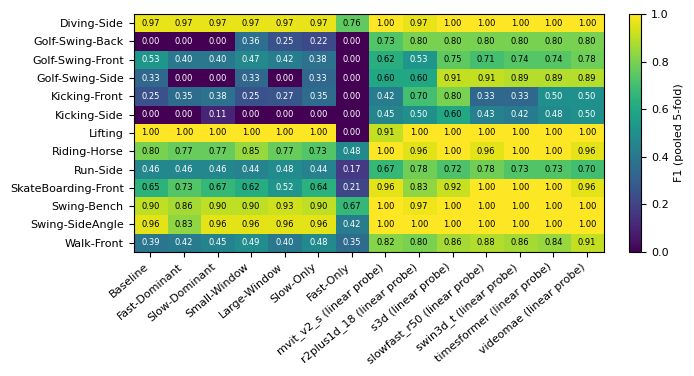

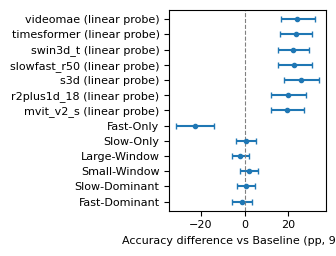

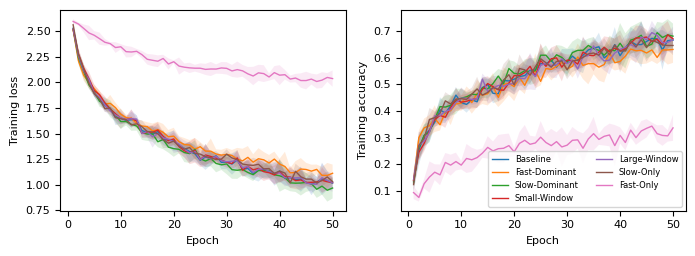

In [32]:
#Figures (PDF = vector for the paper, PNG for preview)
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans", "axes.titlesize": 9})
FIG = RES / "figures"

# (a) per-class F1 heatmap across models — suggested main-text figure
fig, ax = plt.subplots(figsize=(7.0, 3.8))
im = ax.imshow(f1_matrix.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(f1_matrix.shape[1])); ax.set_xticklabels(f1_matrix.columns, rotation=40, ha="right")
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
for i in range(f1_matrix.shape[0]):
    for j in range(f1_matrix.shape[1]):
        v = f1_matrix.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v < 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.03, label="F1 (pooled 5-fold)")
fig.tight_layout(); fig.savefig(FIG / "per_class_f1_heatmap.pdf"); fig.savefig(FIG / "per_class_f1_heatmap.png", dpi=200)
plt.show()

# (b) confusion matrices for every model — supplementary
for model, g in P[P.seed == P.seed.min()].groupby("model"):
    cm = confusion_matrix(g.label, g.pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(4.6, 4.2))
    ax.imshow(cm, cmap="Blues")
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(LABELS); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=6)
    ax.set_yticks(LABELS); ax.set_yticklabels(CLASS_NAMES, fontsize=6)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{model} (143 videos, 5-fold OOF)")
    fig.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9_-]+", "_", model)
    fig.savefig(FIG / f"confusion_{safe}.pdf"); fig.savefig(FIG / f"confusion_{safe}.png", dpi=200); plt.close(fig)

# (c) accuracy with 95% CI of the difference to baseline — optional main-text figure
if len(tests):
    t0_ = tests[tests.seed == tests.seed.min()].set_index("model")
    t0_ = t0_.loc[[m for m in order if m in t0_.index]]
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    y = np.arange(len(t0_))
    ax.errorbar(t0_.acc_diff * 100, y, xerr=[(t0_.acc_diff - t0_.acc_ci_low) * 100, (t0_.acc_ci_high - t0_.acc_diff) * 100],
                fmt="o", ms=3, capsize=2)
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.set_yticks(y); ax.set_yticklabels(t0_.index); ax.set_xlabel(f"Accuracy difference vs {BASELINE_NAME} (pp, 95% CI)")
    fig.tight_layout(); fig.savefig(FIG / "accuracy_diff_ci.pdf"); fig.savefig(FIG / "accuracy_diff_ci.png", dpi=200)
    plt.show()

# (d) training curves (mean ± SD over folds) for each SlowFast configuration — supplementary
H = []
for f in (RES / "histories").glob("*.csv"):
    m, s, k = f.stem.split("__"); h = pd.read_csv(f); h["model"] = m; h["seed"] = s; H.append(h)
if H:
    H = pd.concat(H)
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    for m in [m for m in order if m in set(H.model)]:
        g = H[H.model == m].groupby("epoch")
        for ax, col in zip(axes, ["train_loss", "train_acc"]):
            mu, sd = g[col].mean(), g[col].std()
            ax.plot(mu.index, mu.values, label=m, lw=1); ax.fill_between(mu.index, mu - sd, mu + sd, alpha=0.15)
    axes[0].set_ylabel("Training loss"); axes[1].set_ylabel("Training accuracy")
    for ax in axes: ax.set_xlabel("Epoch")
    axes[1].legend(fontsize=6, ncol=2)
    fig.tight_layout(); fig.savefig(FIG / "training_curves.pdf"); fig.savefig(FIG / "training_curves.png", dpi=200)
    plt.show()

In [33]:
def pm(m, s):
    return f"{100 * m:.2f} $\\pm$ {100 * s:.2f}" if pd.notna(s) else f"{100 * m:.2f}"

tex = summary.copy()
tex["Accuracy (\\%)"] = [pm(m, s) for m, s in zip(tex.acc_mean, tex.acc_sd)]
tex["Macro-F1 (\\%)"] = [pm(m, s) for m, s in zip(tex.f1_mean, tex.f1_sd)]
tex["Params (M)"] = (tex.params / 1e6).round(2)
tex = tex[["model", "Params (M)", "GFLOPs", "Accuracy (\\%)", "Macro-F1 (\\%)"]].rename(columns={"model": "Model"})
(RES / "tables" / "main_results.tex").write_text(tex.to_latex(index=False, escape=False, na_rep="--"))
(RES / "tables" / "architecture_configs.tex").write_text(arch_df.to_latex(index=False))
if len(tests):
    tt = tests[["seed", "model", "acc_diff", "acc_ci_low", "acc_ci_high", "f1_diff", "mcnemar_p", "mcnemar_p_holm"]].copy()
    (RES / "tables" / "significance_vs_baseline.tex").write_text(tt.to_latex(index=False, float_format="%.3f"))

import sklearn, torchvision
env = dict(python=sys.version, platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, sklearn=sklearn.__version__, numpy=np.__version__,
           opencv=cv2.__version__, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
           n_videos=len(index_df), date=time.strftime("%Y-%m-%d"))
json.dump(env, open(RES / "environment.json", "w"), indent=2)
shutil.make_archive(str(WORK / "results_archive"), "zip", RES)
print(json.dumps(env, indent=2))
print("All outputs in", RES, "and", WORK / "results_archive.zip")

{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "sklearn": "1.6.1",
  "numpy": "2.1.3",
  "opencv": "4.14.0",
  "gpu": "Tesla T4",
  "n_videos": 150,
  "date": "2026-10-27"
}
All outputs in /kaggle/working/UCF_Sports_Action/results and /kaggle/working/UCF_Sports_Action/results_archive.zip
